In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import os

os.listdir("/content")

['.config', 'base_trabajo_desigualdad_justicia.xlsx', 'sample_data']

In [ ]:
archivo = "/content/base_trabajo_desigualdad_justicia.xlsx"

df = pd.read_excel(
    archivo,
    sheet_name="04_Base_analisis"
)

df.head()

,Comunidad,Año,arope (%),Población,Solicitudes,expedientes_tramite,expedientes_remitidos,expedientes_concedidos,expedientes_denegados,solicitudes_por_1000_hab,tasa_concesion_resoluciones_pct
0,01 Andalucía,2024.0,36.0,8631862,223038,76304,158990,74902,16506,25.838921,NaN
1,02 Aragón,2024.0,20.8,1351591,17974,3471,13391,10656,2227,13.298402,NaN
2,"03 Asturias, Principado de",2024.0,21.9,1009599,16406,3204,12551,5966,1016,16.250016,NaN
3,"04 Balears, Illes",2024.0,17.0,1231768,34238,747,32443,28076,2714,27.795819,NaN
4,05 Canarias,2024.0,31.8,2238754,32150,11060,21557,12467,1315,14.360667,NaN


In [ ]:
print("Dimensiones:", df.shape)

print("\nColumnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

print("\nValores ausentes:")
print(df.isna().sum())

Dimensiones: (18, 11)

Columnas:
['Comunidad', 'Año', 'arope (%)', 'Población', 'Solicitudes', 'expedientes_tramite', 'expedientes_remitidos', 'expedientes_concedidos', 'expedientes_denegados', 'solicitudes_por_1000_hab', 'tasa_concesion_resoluciones_pct']

Tipos de datos:
Comunidad                           object
Año                                float64
arope (%)                          float64
Población                            int64
Solicitudes                          int64
expedientes_tramite                  int64
expedientes_remitidos                int64
expedientes_concedidos               int64
expedientes_denegados                int64
solicitudes_por_1000_hab           float64
tasa_concesion_resoluciones_pct    float64
dtype: object

Valores ausentes:
Comunidad                           0
Año                                 1
arope (%)                           1
Población                           0
Solicitudes                         0
expedientes_tramite           

In [ ]:
print("Dimensiones:", df.shape)

print("\nÚltimas 5 filas:")
display(df.tail())

print("\nFilas con valores ausentes:")
display(df[df.isna().any(axis=1)])

print("\nNúmero de valores ausentes por columna:")
print(df.isna().sum()

Dimensiones: (18, 11)

Últimas 5 filas:


,Comunidad,Año,arope (%),Población,Solicitudes,expedientes_tramite,expedientes_remitidos,expedientes_concedidos,expedientes_denegados,solicitudes_por_1000_hab,tasa_concesion_resoluciones_pct
13,"14 Murcia, Región de",2024.0,33.8,1568492,41085,2459,37141,25699,1894,26.193949,NaN
14,"15 Navarra, Comunidad Foral de",2024.0,17.7,678333,14415,1837,13676,10439,1250,21.250625,NaN
15,16 País Vasco,2024.0,15.5,2227684,25996,1538,25751,14162,2777,11.669519,NaN
16,"17 Rioja, La",2024.0,23.1,324184,4606,421,4265,3177,620,14.207981,NaN
17,Total,NaN,NaN,48450531,1127855,202686,935914,562429,94142,NaN,NaN



Filas con valores ausentes:


,Comunidad,Año,arope (%),Población,Solicitudes,expedientes_tramite,expedientes_remitidos,expedientes_concedidos,expedientes_denegados,solicitudes_por_1000_hab,tasa_concesion_resoluciones_pct
0,01 Andalucía,2024.0,36.0,8631862,223038,76304,158990,74902,16506,25.838921,NaN
1,02 Aragón,2024.0,20.8,1351591,17974,3471,13391,10656,2227,13.298402,NaN
2,"03 Asturias, Principado de",2024.0,21.9,1009599,16406,3204,12551,5966,1016,16.250016,NaN
3,"04 Balears, Illes",2024.0,17.0,1231768,34238,747,32443,28076,2714,27.795819,NaN
4,05 Canarias,2024.0,31.8,2238754,32150,11060,21557,12467,1315,14.360667,NaN
5,06 Cantabria,2024.0,23.2,590851,8797,1742,6585,5366,1082,14.888694,NaN
6,07 Castilla y León,2024.0,24.0,2391682,41475,2880,37926,28946,6337,17.341352,NaN
7,08 Castilla - La Mancha,2024.0,34.7,2104433,39399,6474,31042,24175,4014,18.721908,NaN
8,09 Cataluña,2024.0,20.7,8012231,267982,28486,231917,129385,17048,33.446614,NaN
9,10 Comunitat Valenciana,2024.0,29.9,5319285,127898,18475,120732,80896,17463,24.044209,NaN



Número de valores ausentes por columna:
Comunidad                           0
Año                                 1
arope (%)                           1
Población                           0
Solicitudes                         0
expedientes_tramite                 0
expedientes_remitidos               0
expedientes_concedidos              0
expedientes_denegados               0
solicitudes_por_1000_hab            1
tasa_concesion_resoluciones_pct    18
dtype: int64


In [ ]:
print("Comunidades distintas:", df["Comunidad"].nunique())

print("\nPosibles Comunidades duplicadas:")
display(
    df[df["Comunidad"].duplicated(keep=False)]
    .sort_values("Comunidad")
)

Comunidades distintas: 18

Posibles Comunidades duplicadas:


,Comunidad,Año,arope (%),Población,Solicitudes,expedientes_tramite,expedientes_remitidos,expedientes_concedidos,expedientes_denegados,solicitudes_por_1000_hab,tasa_concesion_resoluciones_pct


In [ ]:
# Excluir la fila de total
df_analisis = df.iloc[:-1].copy()

print("Número de filas:", len(df_analisis))
display(df_analisis.head())

Número de filas: 17


,Comunidad,Año,arope (%),Población,Solicitudes,expedientes_tramite,expedientes_remitidos,expedientes_concedidos,expedientes_denegados,solicitudes_por_1000_hab,tasa_concesion_resoluciones_pct
0,01 Andalucía,2024.0,36.0,8631862,223038,76304,158990,74902,16506,25.838921,NaN
1,02 Aragón,2024.0,20.8,1351591,17974,3471,13391,10656,2227,13.298402,NaN
2,"03 Asturias, Principado de",2024.0,21.9,1009599,16406,3204,12551,5966,1016,16.250016,NaN
3,"04 Balears, Illes",2024.0,17.0,1231768,34238,747,32443,28076,2714,27.795819,NaN
4,05 Canarias,2024.0,31.8,2238754,32150,11060,21557,12467,1315,14.360667,NaN


In [ ]:
variables = [
    "arope (%)",
    "solicitudes_por_1000_hab"
]

estadisticas = df_analisis[variables].describe().T

display(estadisticas)

,count,mean,std,min,25%,50%,75%,max
arope (%),17.0,24.870588,6.794277,15.500000,20.700000,23.100000,31.800000,36.000000
solicitudes_por_1000_hab,17.0,19.904074,6.038542,11.669519,14.888694,18.721908,24.044209,33.446614


In [ ]:
correlacion = df_analisis["arope (%)"].corr(
    df_analisis["solicitudes_por_1000_hab"]
)

print("Correlación de Pearson:", round(correlacion, 3))

Correlación de Pearson: 0.097


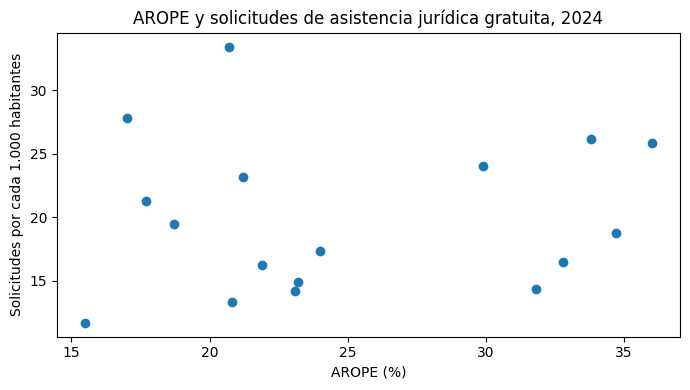

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.scatter(
    df_analisis["arope (%)"],
    df_analisis["solicitudes_por_1000_hab"]
)

plt.xlabel("AROPE (%)")
plt.ylabel("Solicitudes por cada 1.000 habitantes")
plt.title("AROPE y solicitudes de asistencia jurídica gratuita, 2024")

plt.tight_layout()
plt.show()

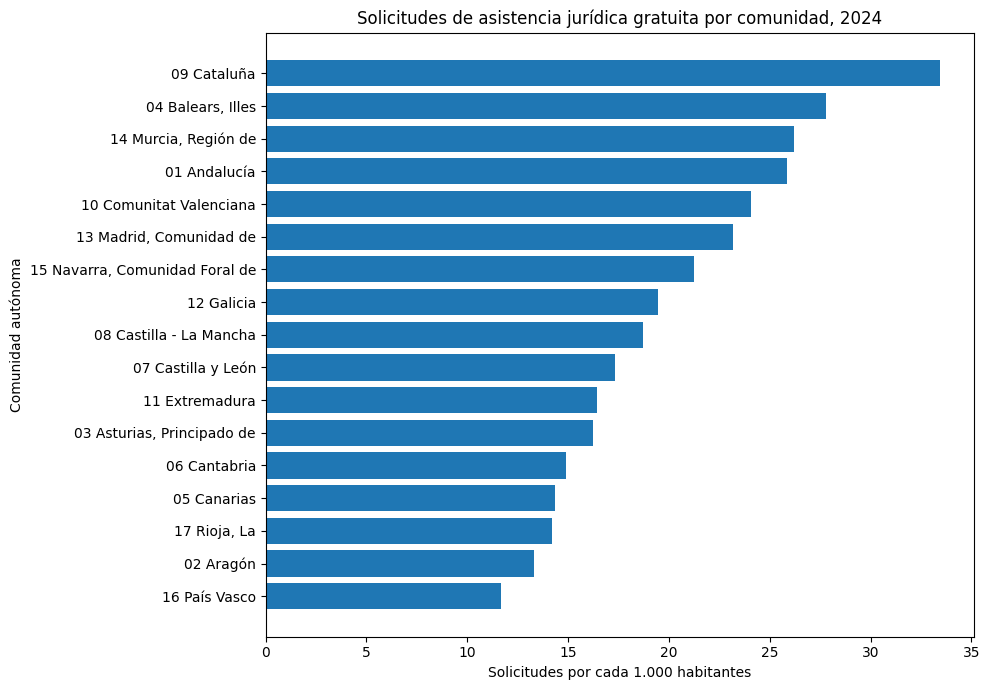

In [ ]:
ranking = df_analisis.sort_values(
    "solicitudes_por_1000_hab",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    ranking["Comunidad"],
    ranking["solicitudes_por_1000_hab"]
)

plt.xlabel("Solicitudes por cada 1.000 habitantes")
plt.ylabel("Comunidad autónoma")
plt.title(
    "Solicitudes de asistencia jurídica gratuita por comunidad, 2024"
)

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import spearmanr

rho, p_valor = spearmanr(
    df_analisis["arope (%)"],
    df_analisis["solicitudes_por_1000_hab"]
)

print("Correlación de Spearman:", round(rho, 3))
print("Valor p:", round(p_valor, 4))

Correlación de Spearman: 0.088
Valor p: 0.7363


In [ ]:
df_analisis.to_csv(
    "base_analisis_17_comunidades.csv",
    index=False,
    encoding="utf-8-sig"
)